# ECE 5831 - HW#7: Neural Network with Backpropagation

In this homework we will be implementing backpropagation. From what we learned in class, it calculates how meach each weight and bias contributes to our networks prediction error. We use the gradient to update the networks weights and biases to redcue the loss. What I saw from the last assignment when just using forward propagation, the MNIST network took a very long time to train. Now if we add the backpropagation we are able to cut that time by a lot as demosntrated in this journal. The way this works is we first do the forward propagation where the network recives a MNIST digit. From there the the predicted outputnis compared to the actual digit. Then the network calculates the gradient and adjusts the weights and biases to reduce the error. It keeps doing this for every batch.

First we will import NumPy, matplotlib, and tensorflow keras datasets to create our class, plot our losses, and aquire our datasets. We aquried our MNIST dataset through keras.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow.keras as keras
from tensorflow.keras import layers


from tensorflow.keras.datasets import mnist


Next we need to implement our TwoLayerNetBackprop. This class is essentially the same one from the last assignment (TwoLayerNet) except this time it contains the backpropagation features and the gradient function:

In [ ]:
class TwoLayerNetBackprop:
    def __init__(self, input_size = 28*28, hidden_size = 100, output_size = 10, weight_init_std = 0.01):
        self.params = {}
        self.params["w1"] = ( weight_init_std * np.random.randn(input_size, hidden_size))
        self.params["b1"] = np.zeros(hidden_size)
        self.params["w2"] = (weight_init_std *np.random.randn(hidden_size, output_size))
        self.params["b2"] = np.zeros(output_size)

    def relu(self,s):
        return np.maximum(0, s)

    def relu_grad(self, s):
        grad = np.zeros_like(s)
        grad[s > 0] = 1
        return grad

    def softmax(self, s):
        if s.ndim == 1:
            s = s - np.max(s)
            exp_s = np.exp(s)
            return exp_s / np.sum(exp_s)
        else:
            s = s - np.max(s, axis=1, keepdims=True)
            exp_s = np.exp(s)
            return exp_s / np.sum( exp_s, axis=1, keepdims=True)

    def predict(self, x):
        w1 = self.params["w1"]
        b1 = self.params["b1"]
        w2 = self.params["w2"]
        b2 = self.params["b2"]
        # Layer 1
        a1 = x @ w1 + b1
        z1 = self.relu(a1)
        # Layer 2
        a2 = z1 @ w2 + b2
        # Output
        yhat = self.softmax(a2)
        return yhat

    # Cross-Entropy Loss
    def cross_entropy_error(self, y, yhat):
        if y.ndim == 1:
            y = y.reshape(1, y.size)
            yhat = yhat.reshape(1, yhat.size)
        batch_size = y.shape[0]
        return -np.sum(y * np.log(yhat + 1e-7)) / batch_size

    # Loss
    def loss(self, x, y):
        yhat = self.predict(x)
        return self.cross_entropy_error(y, yhat)

    def gradient(self, x, y):
        w1 = self.params["w1"]
        b1 = self.params["b1"]
        w2 = self.params["w2"]
        b2 = self.params["b2"]
        # Make sure x and y are batches
        if x.ndim == 1:
            x = x.reshape(1, -1)
        if y.ndim == 1:
            y = y.reshape(1, -1)
        batch_size = x.shape[0]
        # FORWARD PROPAGATION
        a1 = x @ w1 + b1
        z1 = self.relu(a1)
        # Hidden -> Output
        a2 = z1 @ w2 + b2
        yhat = self.softmax(a2)
        da2 = (yhat - y) / batch_size
        dw2 = z1.T @ da2
        db2 = np.sum(da2, axis=0)
        dz1 = da2 @ w2.T
        da1 = dz1 * self.relu_grad(a1)
        dw1 = x.T @ da1
        db1 = np.sum(da1, axis=0)
        grad = {}

        grad["w1"] = dw1
        grad["b1"] = db1
        grad["w2"] = dw2
        grad["b2"] = db2
        return grad
        
        

Next we need to load our datasets. Just like the last assignment we will have one set for training and one set for testing. Each set has its inputs and output labels. we also perfrom the onehot encoding too for this assignment:

In [4]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()


print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train = X_train.reshape(60000, 784).astype("float32")/255.0
X_test = X_test.reshape(10000, 784).astype("float32")/255.0

y_train_onehot = np.eye(10)[y_train]
y_test_onehot = np.eye(10)[y_test]

X_train: (60000, 28, 28)
y_train: (60000,)
X_test: (10000, 28, 28)
y_test: (10000,)


# Training:
Next we need to train our model. We will use a learning rate of 0.1 and each of our batches will have 64 size. We then implement our network and create it and from there we do the training. One thing we need to do is shuffle the dataset that way when we go trough the training 10 times, each time we are doing a differenet orientation of the dataset. From there we sort our data set into batches and we perfrom the back propagation. From there we use our calculated gradient and we adjust our networks weights and biases using the combination of the learning rate and gradient. From there we do our calculation of our loss and accuracy of each epoch. Our training does this 10 times as shown as epochs = 10. After each iteration we calculate the accuracy and loss.

In [5]:
# Training Settings

epochs = 10
learning_rate = 0.1
batch_size = 64

train_loss_list = []
train_acc_list = []

network = TwoLayerNetBackprop( input_size = 28*28, hidden_size= 100, output_size=10)

for epoch in range (epochs):
    indices = np.random.permutation(len(X_train))
    X_train_shuffled = X_train[indices]
    y_train_shuffled = y_train_onehot[indices]

    for i in range(0, len(X_train), batch_size):
        x_batch = X_train_shuffled[i: i+batch_size]
        y_batch = y_train_shuffled[i: i+batch_size]

        #Backpropagation
        grad = network.gradient(x_batch, y_batch)

        for key in network.params.keys():
            network.params[key] -= (learning_rate * grad[key])

    loss = network.loss(X_train, y_train_onehot)
    train_loss_list.append(loss)

    y_pred = network.predict(X_train)
    predicted_class = np.argmax(y_pred, axis=1)

    true_class = y_train

    accuracy = np.mean(predicted_class == true_class)
    train_acc_list.append(accuracy)

    print(f"Epoch: {epoch+1:2d}/{epochs} | "
          f"Loss: {loss:.4f} | "
          f"Accuracy: {accuracy:.4f}")
    

Epoch:  1/10 | Loss: 0.2928 | Accuracy: 0.9162
Epoch:  2/10 | Loss: 0.2050 | Accuracy: 0.9428
Epoch:  3/10 | Loss: 0.1583 | Accuracy: 0.9558
Epoch:  4/10 | Loss: 0.1312 | Accuracy: 0.9633
Epoch:  5/10 | Loss: 0.1111 | Accuracy: 0.9673
Epoch:  6/10 | Loss: 0.0989 | Accuracy: 0.9722
Epoch:  7/10 | Loss: 0.0840 | Accuracy: 0.9765
Epoch:  8/10 | Loss: 0.0761 | Accuracy: 0.9783
Epoch:  9/10 | Loss: 0.0642 | Accuracy: 0.9831
Epoch: 10/10 | Loss: 0.0629 | Accuracy: 0.9828


What we saw after each training iteration we see that the loss keeps decreasing and the accuracy keeps on increasing. Next we test to see how the network did and we see that the test accuracy is 97.39% which is extremly high compared to our previous assignment where it required lots of computational power to train the network with only forward propagation. The forward propagation only had a extremely low accuracy form the last assignment because we were not able to train the model as much due to insufficient hardware.

In [6]:
# Test the neural network

# Forward propagation on test images
y_test_pred = network.predict(X_test)

# Get predicted digit (0-9)
predicted_class = np.argmax(y_test_pred, axis=1)

# Compare predictions with actual labels
accuracy = np.mean(predicted_class == y_test)

# Display results
print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 0.9739
Test Accuracy: 97.39%


Here we plot our training loss and trinaing accuracy and what we should see is an increase in accuracy and a decrease in loss as we keep training our network through back propagation. The forward propagation only from the last assignment a extremly high loss and low accuracy because we couldnt train our model as much due to insufficient hardware.

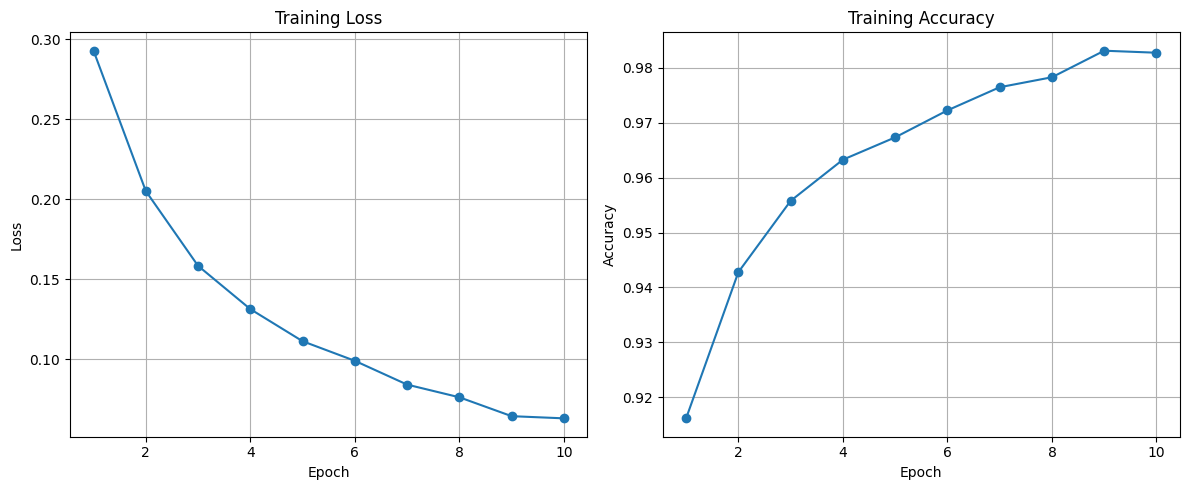

In [11]:

plt.figure(figsize=(12, 5))

# Training Loss
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs + 1), train_loss_list, marker='o')
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)

# Training Accuracy
plt.subplot(1, 2, 2)
plt.plot(range(1, epochs + 1), train_acc_list, marker='o')
plt.title('Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(True)

plt.tight_layout()
plt.show()

# Testing:

Now lets do some testing with our network. Because of how big our training data set is, we will only test the first 50 images of the data set. What we see is that the network was correct for almost all of the predictions. We see image 9 where the prediction was 6 but the actual was 5. I saw this in the first time we implemented the MNIST neural network is that there tends to be similarities in 5 and 6 like if the loop isnt completed or something like that. Like in the last assignment we only did forward propagation and we saw that it virtually failed prediciting the correct number on every test case and here we see lots of improvement. 

In [ ]:

y_pred = network.predict(X_test[:50])

predicted_class = np.argmax(y_pred, axis=1)

for i in range(50):
    print(
        f"Image {i+1} | "
        f"Predicted: {predicted_class[i]} | "
        f"Actual: {y_test[i]} | "
    )
    if predicted_class[i] == y_test[i]:
        print(f"Correct")
    else:
        print(f"Incorrect")
        

Image 1 | Predicted: 7 | Actual: 7 | 
Correct
Image 2 | Predicted: 2 | Actual: 2 | 
Correct
Image 3 | Predicted: 1 | Actual: 1 | 
Correct
Image 4 | Predicted: 0 | Actual: 0 | 
Correct
Image 5 | Predicted: 4 | Actual: 4 | 
Correct
Image 6 | Predicted: 1 | Actual: 1 | 
Correct
Image 7 | Predicted: 4 | Actual: 4 | 
Correct
Image 8 | Predicted: 9 | Actual: 9 | 
Correct
Image 9 | Predicted: 6 | Actual: 5 | 
Incorrect
Image 10 | Predicted: 9 | Actual: 9 | 
Correct
Image 11 | Predicted: 0 | Actual: 0 | 
Correct
Image 12 | Predicted: 6 | Actual: 6 | 
Correct
Image 13 | Predicted: 9 | Actual: 9 | 
Correct
Image 14 | Predicted: 0 | Actual: 0 | 
Correct
Image 15 | Predicted: 1 | Actual: 1 | 
Correct
Image 16 | Predicted: 5 | Actual: 5 | 
Correct
Image 17 | Predicted: 9 | Actual: 9 | 
Correct
Image 18 | Predicted: 7 | Actual: 7 | 
Correct
Image 19 | Predicted: 3 | Actual: 3 | 
Correct
Image 20 | Predicted: 4 | Actual: 4 | 
Correct
Image 21 | Predicted: 9 | Actual: 9 | 
Correct
Image 22 | Predicted

# Conclusion:
In conclusion we saw how backpropagation is very helpful when dealing with very large networks and massive datasets. As shown it shortens the time a lot more when training these networks. We also saw how we are able to implement the gradient inorder to do the back propagation. Then we saw how the loss decreases and the accruacy increases as we keep training our network. Compared to just doing the forward propagation where we ahd horrible accuracy and huge loss because we couldnt train the model as much due to insufficient hardware, using both forward and back propogation helped a lot in getting that really high accuracy and low loss.